# Transfer Learning Layer Freezing Strategy

This notebook fine-tunes an ImageNet-pretrained ResNet50 on the crowd-density dataset in `data/` and compares four freezing strategies: no freezing, early-layer freezing, late-layer freezing, and all-but-head freezing.

> **Setup.** This notebook expects the crowd-density images at `data/data/{high_new1,low_new1,medium_new1}/` (see [`DATA.md`](../DATA.md)). The dataset is **not** included in this repository. The original `!unzip data.zip -d data` cell is kept for Colab use; skip it if the folders are already in place.
>
> Saved outputs are from the original Colab run (GPU, seed 42). Training uses Adam, lr = 1e-3, no weight decay, no LR scheduler.


**All the results are at the end of this notebook.**




In [1]:
!unzip data.zip -d data

## Imports

In [2]:
import copy
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from torch.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import ImageFolder

sns.set_theme(style="whitegrid")


## Configuration

In [9]:
# Config
SEED = 42
DATA_ROOT = "data/data"
BATCH_SIZE = 32
EPOCHS = 15
LR = 1e-3
NUM_WORKERS = 0


## Dataset Utilities

In [10]:
CLASS_NAMES = ["low", "medium", "high"]


class SafeDataset(Dataset):
    def __init__(self, base, indices, transform, folder_remap):
        self.base = base
        self.indices = indices
        self.transform = transform
        self.folder_remap = folder_remap

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        while True:
            path, label = self.base.samples[self.indices[i]]
            try:
                img = Image.open(path).convert("RGB")
                img = self.transform(img)
                return img, self.folder_remap[label]
            except Exception as exc:
                print(f"Skipping unreadable image: {path} ({exc})")
                i = (i + 1) % len(self.indices)


def build_folder_remap(class_to_idx):
    remap = {}
    for folder_name, folder_idx in class_to_idx.items():
        normalized = folder_name.lower()
        if "low" in normalized:
            remap[folder_idx] = CLASS_NAMES.index("low")
        elif "medium" in normalized or "mid" in normalized:
            remap[folder_idx] = CLASS_NAMES.index("medium")
        elif "high" in normalized:
            remap[folder_idx] = CLASS_NAMES.index("high")
        else:
            raise ValueError(
                f"Cannot infer crowd-density label from folder '{folder_name}'. "
                "Folder names should contain low, medium, or high."
            )

    if sorted(remap.values()) != list(range(len(CLASS_NAMES))):
        raise ValueError(f"Expected one folder for each class {CLASS_NAMES}, got {class_to_idx}")

    return remap


## Model And Freezing Strategies

In [11]:
def build_model(strategy, device):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

    if strategy == "S1_freeze_early":
        for name, p in model.named_parameters():
            if any(name.startswith(x) for x in ["conv1", "bn1", "layer1", "layer2"]):
                p.requires_grad = False

    elif strategy == "S2_freeze_late":
        for name, p in model.named_parameters():
            if any(name.startswith(x) for x in ["layer3", "layer4"]):
                p.requires_grad = False

    elif strategy == "S3_all_but_head":
        for name, p in model.named_parameters():
            if not name.startswith("fc"):
                p.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, len(CLASS_NAMES))
    return model.to(device)


## Training And Evaluation Helpers

In [12]:
def train_epoch(model, loader, optimizer, scaler, criterion, device):
    model.train()
    total_loss, correct = 0, 0

    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()

        with autocast(device_type=device, enabled=(device == "cuda")):
            out = model(imgs)
            loss = criterion(out, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * len(labels)
        correct += (out.argmax(1) == labels).sum().item()

    return total_loss / len(loader.dataset), correct / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    preds, labels_all = [], []

    for imgs, labels in loader:
        imgs = imgs.to(device)
        out = model(imgs)
        pred = out.argmax(1).cpu().numpy()

        preds.extend(pred)
        labels_all.extend(labels.numpy())

    acc = np.mean(np.array(preds) == np.array(labels_all))
    return acc, preds, labels_all


## Comparison Table And Recommendation Helpers

In [13]:
def results_to_dataframe(results):
    rows = []
    for strategy, metrics in results.items():
        rows.append(
            {
                "strategy": strategy,
                "best_val_acc": metrics["best_val_acc"],
                "test_acc": metrics["test_acc"],
                "time_sec": metrics["time_sec"],
                "best_epoch_overfit_gap": metrics["best_epoch_overfit_gap"],
                "final_overfit_gap": metrics["final_overfit_gap"],
                "best_epoch": metrics["best_epoch"],
            }
        )
    df = pd.DataFrame(rows)
    return df.sort_values(["test_acc", "best_val_acc"], ascending=False).reset_index(drop=True)


def plot_strategy_histories(histories):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for strategy, history_df in histories.items():
        axes[0].plot(history_df["epoch"], history_df["train_acc"], marker="o", label=f"{strategy} train")
        axes[0].plot(history_df["epoch"], history_df["val_acc"], marker="x", linestyle="--", label=f"{strategy} val")
        axes[1].plot(history_df["epoch"], history_df["overfit_gap"], marker="o", label=strategy)

    axes[0].set_title("Training vs Validation Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend(fontsize=8, ncol=2)

    axes[1].set_title("Overfitting Gap by Epoch")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Train Accuracy - Validation Accuracy")
    axes[1].axhline(0.0, color="black", linewidth=1, alpha=0.5)
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    plt.show()


def plot_comparison_dashboard(results_df):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    order = results_df.sort_values("test_acc", ascending=False)["strategy"]

    sns.barplot(data=results_df, x="strategy", y="test_acc", order=order, ax=axes[0, 0], palette="Blues_d")
    axes[0, 0].set_title("Test Accuracy by Freezing Strategy")
    axes[0, 0].set_xlabel("")
    axes[0, 0].set_ylabel("Test Accuracy")

    sns.barplot(data=results_df, x="strategy", y="best_val_acc", order=order, ax=axes[0, 1], palette="Greens_d")
    axes[0, 1].set_title("Best Validation Accuracy")
    axes[0, 1].set_xlabel("")
    axes[0, 1].set_ylabel("Validation Accuracy")

    sns.barplot(data=results_df, x="strategy", y="time_sec", order=order, ax=axes[1, 0], palette="Oranges_d")
    axes[1, 0].set_title("Training Time")
    axes[1, 0].set_xlabel("")
    axes[1, 0].set_ylabel("Seconds")

    gap_df = results_df[["strategy", "best_epoch_overfit_gap", "final_overfit_gap"]].melt(
        id_vars="strategy",
        var_name="gap_type",
        value_name="gap",
    )
    sns.barplot(data=gap_df, x="strategy", y="gap", hue="gap_type", order=order, ax=axes[1, 1], palette="Set2")
    axes[1, 1].set_title("Overfitting Comparison")
    axes[1, 1].set_xlabel("")
    axes[1, 1].set_ylabel("Gap")
    axes[1, 1].axhline(0.0, color="black", linewidth=1, alpha=0.5)

    for ax in axes.flat:
        ax.tick_params(axis="x", rotation=15)

    plt.tight_layout()
    plt.show()


def show_classification_reports(report_tables):
    for strategy, report_df in report_tables.items():
        print(f"\nClassification report: {strategy}")
        display(report_df.round(4))


def choose_recommendation(results):
    def score(item):
        _, metrics = item
        overfit_penalty = max(metrics["best_epoch_overfit_gap"], 0)
        return metrics["test_acc"] - 0.25 * overfit_penalty - 0.00001 * metrics["time_sec"]

    best_strategy, best_metrics = max(results.items(), key=score)
    return {
        "recommended_strategy": best_strategy,
        "reason": (
            f"{best_strategy} gives the best balance of test accuracy "
            f"({best_metrics['test_acc']:.4f}), training time "
            f"({best_metrics['time_sec']:.1f}s), and overfitting gap "
            f"({best_metrics['best_epoch_overfit_gap']:.4f})."
        ),
        "general_guidance": (
            "For a small crowd-density dataset, prefer freezing early layers or all but the "
            "classification head when overfitting is high. Fine-tune all layers only if it "
            "clearly improves validation/test accuracy without a large train-validation gap."
        ),
    }


## Run Experiment

Run this cell to train every strategy, save checkpoints, write the comparison table, and print the recommendation.

Using device: cuda
Dataset folders: {'high_new1': 0, 'low_new1': 1, 'medium_new1': 2}
Label remap to ['low', 'medium', 'high']: {0: 2, 1: 0, 2: 1}
Train: 1332 | Val: 285 | Test: 286

===== S0_no_freeze =====
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 194MB/s]


Epoch 1: train=0.753, val=0.804
Epoch 2: train=0.841, val=0.863
Epoch 3: train=0.887, val=0.839
Epoch 4: train=0.865, val=0.558
Epoch 5: train=0.885, val=0.779
Epoch 6: train=0.928, val=0.839
Epoch 7: train=0.929, val=0.895
Epoch 8: train=0.923, val=0.849
Epoch 9: train=0.911, val=0.796
Epoch 10: train=0.929, val=0.775
Epoch 11: train=0.939, val=0.621
Epoch 12: train=0.932, val=0.846
Epoch 13: train=0.938, val=0.821
Epoch 14: train=0.975, val=0.912
Epoch 15: train=0.980, val=0.909
Skipping unreadable image: data/data/high_new1/1894_2.png (cannot identify image file 'data/data/high_new1/1894_2.png')
Test Acc: 0.9091 | Time: 477.4s


,precision,recall,f1-score,support
low,0.8792,0.9850,0.9291,133.0000
medium,0.9079,0.7931,0.8466,87.0000
high,0.9836,0.9091,0.9449,66.0000
accuracy,0.9091,0.9091,0.9091,0.9091
macro avg,0.9236,0.8957,0.9069,286.0000
weighted avg,0.9120,0.9091,0.9076,286.0000



===== S1_freeze_early =====
Epoch 1: train=0.806, val=0.849
Epoch 2: train=0.888, val=0.863
Epoch 3: train=0.914, val=0.835
Epoch 4: train=0.944, val=0.933
Epoch 5: train=0.964, val=0.877
Epoch 6: train=0.969, val=0.916
Epoch 7: train=0.956, val=0.821
Epoch 8: train=0.965, val=0.902
Epoch 9: train=0.975, val=0.912
Epoch 10: train=0.980, val=0.926
Epoch 11: train=0.982, val=0.930
Epoch 12: train=0.974, val=0.789
Epoch 13: train=0.973, val=0.891
Epoch 14: train=0.981, val=0.891
Epoch 15: train=0.974, val=0.800
Skipping unreadable image: data/data/high_new1/1894_2.png (cannot identify image file 'data/data/high_new1/1894_2.png')
Test Acc: 0.9301 | Time: 448.7s


,precision,recall,f1-score,support
low,0.9416,0.9699,0.9556,133.0000
medium,0.9250,0.8506,0.8862,87.0000
high,0.9130,0.9545,0.9333,66.0000
accuracy,0.9301,0.9301,0.9301,0.9301
macro avg,0.9265,0.9250,0.9250,286.0000
weighted avg,0.9300,0.9301,0.9293,286.0000


... (2 outputs left out)


===== S3_all_but_head =====
Epoch 1: train=0.660, val=0.811
Epoch 2: train=0.824, val=0.698
Epoch 3: train=0.833, val=0.825
Epoch 4: train=0.823, val=0.825
Epoch 5: train=0.880, val=0.860
Epoch 6: train=0.877, val=0.881
Epoch 7: train=0.896, val=0.870
Epoch 8: train=0.897, val=0.863
Epoch 9: train=0.882, val=0.842
Epoch 10: train=0.893, val=0.832
Epoch 11: train=0.890, val=0.881
Epoch 12: train=0.893, val=0.867
Epoch 13: train=0.896, val=0.884
Epoch 14: train=0.900, val=0.888
Epoch 15: train=0.890, val=0.881
Skipping unreadable image: data/data/high_new1/1894_2.png (cannot identify image file 'data/data/high_new1/1894_2.png')
Test Acc: 0.8846 | Time: 431.6s


,precision,recall,f1-score,support
low,0.8562,0.9398,0.8961,133.0000
medium,0.8701,0.7701,0.8171,87.0000
high,0.9683,0.9242,0.9457,66.0000
accuracy,0.8846,0.8846,0.8846,0.8846
macro avg,0.8982,0.8781,0.8863,286.0000
weighted avg,0.8863,0.8846,0.8835,286.0000



FINAL COMPARISON


,strategy,best_val_acc,test_acc,time_sec,best_epoch_overfit_gap,final_overfit_gap,best_epoch
0,S1_freeze_early,0.9333,0.9301,448.7,0.0104,0.1745,4
1,S0_no_freeze,0.9123,0.9091,477.4,0.0629,0.0717,14
2,S2_freeze_late,0.9088,0.9021,467.0,0.0484,0.0379,14
3,S3_all_but_head,0.8877,0.8846,431.6,0.0124,0.0097,14


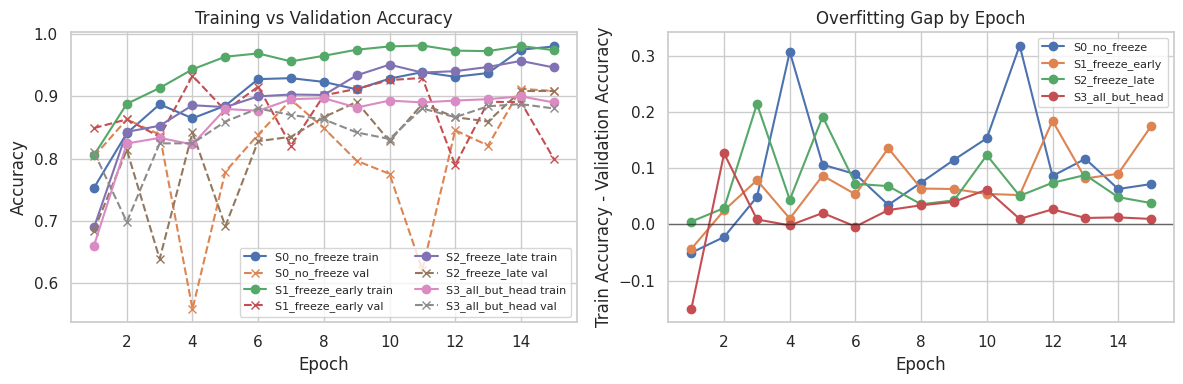

/tmp/ipykernel_2272/1927432040.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="strategy", y="test_acc", order=order, ax=axes[0, 0], palette="Blues_d")
/tmp/ipykernel_2272/1927432040.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="strategy", y="best_val_acc", order=order, ax=axes[0, 1], palette="Greens_d")
/tmp/ipykernel_2272/1927432040.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="strategy", y="time_sec", order=order, ax=axes[1, 0], palette="Oranges_d")


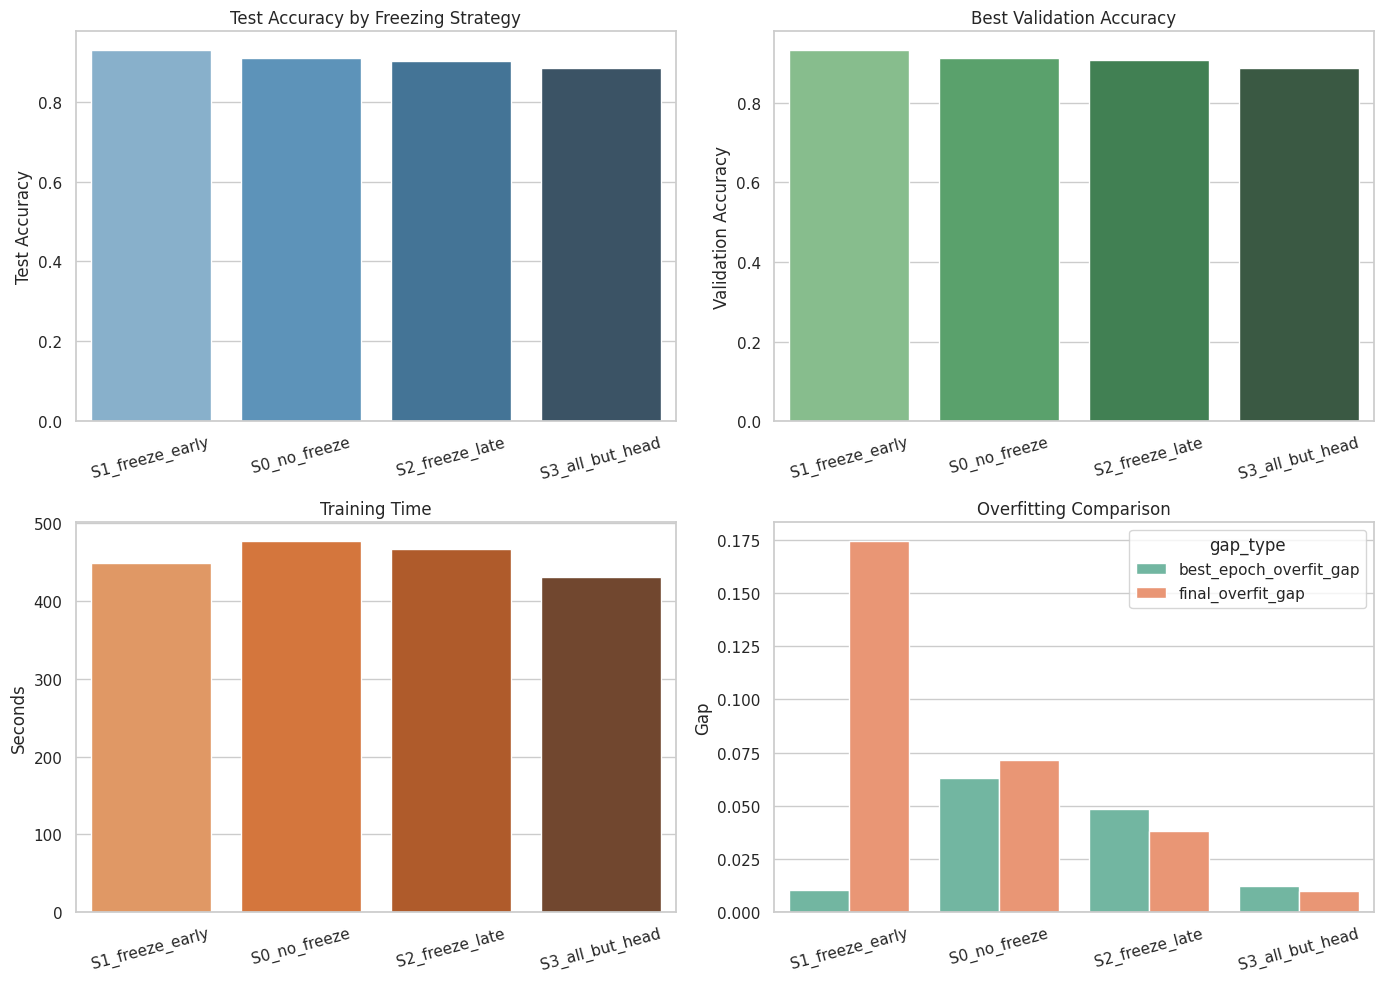


Classification report: S0_no_freeze


,precision,recall,f1-score,support
low,0.8792,0.9850,0.9291,133.0000
medium,0.9079,0.7931,0.8466,87.0000
high,0.9836,0.9091,0.9449,66.0000
accuracy,0.9091,0.9091,0.9091,0.9091
macro avg,0.9236,0.8957,0.9069,286.0000
weighted avg,0.9120,0.9091,0.9076,286.0000



Classification report: S1_freeze_early


,precision,recall,f1-score,support
low,0.9416,0.9699,0.9556,133.0000
medium,0.9250,0.8506,0.8862,87.0000
high,0.9130,0.9545,0.9333,66.0000
accuracy,0.9301,0.9301,0.9301,0.9301
macro avg,0.9265,0.9250,0.9250,286.0000
weighted avg,0.9300,0.9301,0.9293,286.0000



Classification report: S2_freeze_late


,precision,recall,f1-score,support
low,0.9254,0.9323,0.9288,133.0000
medium,0.9221,0.8161,0.8659,87.0000
high,0.8400,0.9545,0.8936,66.0000
accuracy,0.9021,0.9021,0.9021,0.9021
macro avg,0.8958,0.9010,0.8961,286.0000
weighted avg,0.9047,0.9021,0.9016,286.0000



Classification report: S3_all_but_head


,precision,recall,f1-score,support
low,0.8562,0.9398,0.8961,133.0000
medium,0.8701,0.7701,0.8171,87.0000
high,0.9683,0.9242,0.9457,66.0000
accuracy,0.8846,0.8846,0.8846,0.8846
macro avg,0.8982,0.8781,0.8863,286.0000
weighted avg,0.8863,0.8846,0.8835,286.0000



RECOMMENDATION
S1_freeze_early gives the best balance of test accuracy (0.9301), training time (448.7s), and overfitting gap (0.0104).
For a small crowd-density dataset, prefer freezing early layers or all but the classification head when overfitting is high. Fine-tune all layers only if it clearly improves validation/test accuracy without a large train-validation gap.


In [14]:
def main():
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Using device: {device}")

    train_tf = transforms.Compose(
        [
            transforms.Resize((224, 224)),
            transforms.RandomHorizontalFlip(),
            transforms.ColorJitter(0.2, 0.2),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ]
    )

    val_tf = transforms.Compose(
        [
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ]
    )

    base_dataset = ImageFolder(root=DATA_ROOT)
    folder_remap = build_folder_remap(base_dataset.class_to_idx)
    print(f"Dataset folders: {base_dataset.class_to_idx}")
    print(f"Label remap to {CLASS_NAMES}: {folder_remap}")

    labels = [folder_remap[s[1]] for s in base_dataset.samples]
    idx_all = np.arange(len(base_dataset))

    idx_trainval, idx_test = train_test_split(
        idx_all, test_size=0.15, stratify=labels, random_state=SEED
    )

    labels_tv = [labels[i] for i in idx_trainval]

    idx_train, idx_val = train_test_split(
        idx_trainval, test_size=0.176, stratify=labels_tv, random_state=SEED
    )

    print(f"Train: {len(idx_train)} | Val: {len(idx_val)} | Test: {len(idx_test)}")

    def make_loader(indices, tf, shuffle=False):
        return DataLoader(
            SafeDataset(base_dataset, indices, tf, folder_remap),
            batch_size=BATCH_SIZE,
            shuffle=shuffle,
            num_workers=NUM_WORKERS,
            pin_memory=(device == "cuda"),
        )

    train_loader = make_loader(idx_train, train_tf, True)
    val_loader = make_loader(idx_val, val_tf)
    test_loader = make_loader(idx_test, val_tf)

    counts = np.bincount([labels[i] for i in idx_train], minlength=len(CLASS_NAMES))
    counts[counts == 0] = 1
    weights = torch.tensor(1.0 / counts, dtype=torch.float).to(device)

    strategies = [
        "S0_no_freeze",
        "S1_freeze_early",
        "S2_freeze_late",
        "S3_all_but_head",
    ]

    results = {}
    histories = {}
    report_tables = {}

    for strat in strategies:
        print(f"\n===== {strat} =====")

        start = time.time()

        model = build_model(strat, device)
        criterion = nn.CrossEntropyLoss(weight=weights)
        optimizer = torch.optim.Adam(
            filter(lambda p: p.requires_grad, model.parameters()), lr=LR
        )
        scaler = GradScaler(enabled=(device == "cuda"))

        best_val = -1.0
        best_train = 0.0
        best_epoch = 0
        best_state = copy.deepcopy(model.state_dict())
        history = []

        for epoch in range(EPOCHS):
            _, tr_acc = train_epoch(model, train_loader, optimizer, scaler, criterion, device)
            val_acc, _, _ = evaluate(model, val_loader, device)

            history.append(
                {
                    "epoch": epoch + 1,
                    "train_acc": tr_acc,
                    "val_acc": val_acc,
                    "overfit_gap": tr_acc - val_acc,
                }
            )
            print(f"Epoch {epoch + 1}: train={tr_acc:.3f}, val={val_acc:.3f}")

            if val_acc > best_val:
                best_val = val_acc
                best_train = tr_acc
                best_epoch = epoch + 1
                best_state = copy.deepcopy(model.state_dict())

        model.load_state_dict(best_state)
        test_acc, preds, labels_all = evaluate(model, test_loader, device)

        elapsed = time.time() - start
        best_gap = best_train - best_val
        final_gap = history[-1]["overfit_gap"]
        histories[strat] = pd.DataFrame(history)
        report_tables[strat] = pd.DataFrame(
            classification_report(
                labels_all, preds, target_names=CLASS_NAMES, zero_division=0, output_dict=True
            )
        ).T

        results[strat] = {
            "best_val_acc": round(best_val, 4),
            "test_acc": round(test_acc, 4),
            "time_sec": round(elapsed, 1),
            "best_epoch_overfit_gap": round(best_gap, 4),
            "final_overfit_gap": round(final_gap, 4),
            "best_epoch": best_epoch,
        }

        print(f"Test Acc: {test_acc:.4f} | Time: {elapsed:.1f}s")
        display(report_tables[strat].round(4))

    print("\nFINAL COMPARISON")
    results_df = results_to_dataframe(results)
    display(results_df)
    plot_strategy_histories(histories)
    plot_comparison_dashboard(results_df)
    show_classification_reports(report_tables)

    recommendation = choose_recommendation(results)
    print("\nRECOMMENDATION")
    print(recommendation["reason"])
    print(recommendation["general_guidance"])
    return results_df, histories, report_tables, recommendation


results_df, strategy_histories, strategy_reports, recommendation = main()
